# Video Diffusion and LoRA fine-tuning - presentation notebook

Runs **both tasks end to end** and displays the evidence: loss curves, denoising tests, generated images and videos, experiment tables, base-vs-LoRA comparison.

| | Task 1 - diffusion from scratch | Task 2 - LoRA on an open video model |
|---|---|---|
| model | our own UNet (2D for images, 3D for video) | ModelScope text-to-video 1.7B (Hugging Face) + our own LoRA layers |
| data | Fashion-MNIST and synthetic moving shapes | small captioned toy videos (made by `make_toy_dataset.py`) |
| what we implement | noise schedule, forward process, loss, DDPM/DDIM samplers, training loop, metrics | LoRA layers, training loop, validation, per-epoch checkpoints, experiment sweep, evaluation |

**How to use:** Runtime -> Change runtime type -> **T4 GPU**, then *Run all*. Set `QUICK = True` in section 1 first to check that everything works in ~15 minutes, then switch to `False` for the real results.

## 1. Setup

In [1]:
import glob, json, os, subprocess, sys, time
REPO_URL = "https://github.com/Aryam-21/Video-Diffusion-and-LoRA-fine-tuning.git"

def find_root():
    for d, dirs, _ in os.walk("/content"):
        if "task1_diffusion" in dirs and "task2_lora" in dirs:
            return d
        if d.count(os.sep) > 5: dirs[:] = []
    return None

root = find_root()
if root is None:
    subprocess.run(["git", "clone", REPO_URL], cwd="/content", check=True)
    root = find_root()
assert root, "project folder with task1_diffusion/ and task2_lora/ not found - check REPO_URL"
os.chdir(root); sys.path.insert(0, root)
print("project root:", root)

project root: /content/Video-Diffusion-and-LoRA-fine-tuning


In [2]:
# Colab ships an old `torchao` that breaks the newest diffusers import (we do not use it) -> remove, then install requirements
!pip uninstall -y -q torchao
!pip install -q -r requirements.txt
import torch
assert torch.cuda.is_available(), "No GPU: Runtime -> Change runtime type -> T4 GPU, then rerun"
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)

GPU: Tesla T4 | torch 2.11.0+cu130


In [3]:
# ----------------------------- experiment size -----------------------------
QUICK = False
AMP = "--amp"           # mixed precision on the GPU

EP_IMG    = 2 if QUICK else 20       # Task 1 image epochs
EP_VID    = 2 if QUICK else 40       # Task 1 video epochs
EP_ABL    = 2 if QUICK else 8        # Task 1 schedule / loss-weighting ablation (image)
EP_LORA   = 2 if QUICK else 10       # Task 2 epochs per LoRA run
Q1 = "--n_train 256 --max_train 2048 --sample_every 99" if QUICK else ""       # Task 1: cap the data in quick mode
EVAL1 = "--n_samples 64 --n_denoise 16 --guidance 1.0 2.0" if QUICK else "--guidance 1.0 2.0 4.0"
print("QUICK =", QUICK)

QUICK = False


In [4]:
# ----------------------------- display helpers -----------------------------
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import imageio.v2 as iio
from PIL import Image as PILImage, ImageDraw

def pick(pattern, last=False):
    f = sorted(glob.glob(pattern, recursive=True))
    return (f[-1] if last else f[0]) if f else None

def show_png(path, title=None, width=10):
    if not path or not os.path.exists(path): print("[missing]", path); return
    img = plt.imread(path); h = max(1.5, width * img.shape[0] / img.shape[1])
    plt.figure(figsize=(width, h)); plt.imshow(img, cmap="gray" if img.ndim == 2 else None); plt.axis("off")
    if title: plt.title(title, fontsize=11)
    plt.show()

def show_gif(path, title=None, width=480):
    if not path or not os.path.exists(path): print("[missing]", path); return
    if title: print(title)
    display(Image(data=open(path, "rb").read(), format="gif", width=width))      # embedded -> works in Colab

def show_md(path):
    display(Markdown(open(path).read())) if os.path.exists(path) else print("[missing]", path)

def read_frames(path):
    try: return np.stack(iio.mimread(path, memtest=False))
    except Exception: return np.stack(iio.mimread(path, memtest=False, format="GIF"))

def side_by_side(paths, labels, out, fps=6, width=None):
    """Put several clips next to each other (same frame index) with a text label on each; save as a GIF."""
    vids = [read_frames(p) for p in paths]; T = min(len(v) for v in vids); frames = []
    for t in range(T):
        tiles = []
        for v, lab in zip(vids, labels):
            im = PILImage.fromarray(v[t][..., :3].astype(np.uint8)).convert("RGB")
            ImageDraw.Draw(im).rectangle([0, 0, 8 + 7 * len(lab), 14], fill=(0, 0, 0))
            ImageDraw.Draw(im).text((4, 2), lab, fill=(255, 255, 255)); tiles.append(np.asarray(im))
        frames.append(np.concatenate(tiles, axis=1))
    iio.mimsave(out, frames, duration=1.0 / fps, loop=0)
    show_gif(out, width=width or min(1100, frames[0].shape[1]))

# 2. Task 1 - a diffusion model written from scratch

**Forward process** (fixed, no learning): `x_t = sqrt(a_t) * x_0 + sqrt(1 - a_t) * eps`, where `a_t` (alpha-bar) falls from ~1 to ~0 over `T` steps - the picture is destroyed gradually.

**Training:** pick a random `t`, noise a clean sample, ask the network to predict the noise `eps`; loss = mean squared error. The network also receives `t` (timestep conditioning) and the class label.

**Sampling:** start from pure noise and repeatedly remove the predicted noise (DDPM: 1000 stochastic steps, DDIM: ~50 deterministic steps).

### 2.1 Data and preprocessing (image vs video)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 169kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.15MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.5MB/s]


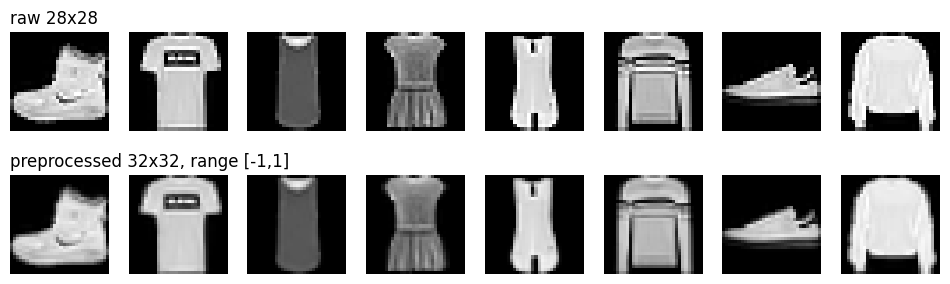

preprocessed tensor: (8, 1, 32, 32) min/max -1.0 0.9866114854812622


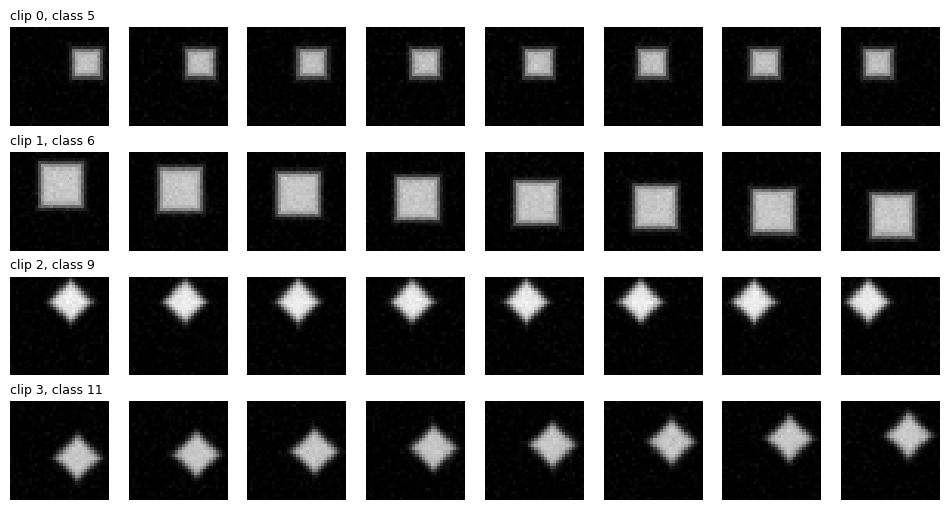

video tensor per clip: (1, 8, 32, 32) (channels, frames, H, W) - the extra TIME axis is what makes video costlier


In [12]:
import torch
from torchvision import datasets
from task1_diffusion import preprocessing as P
from task1_diffusion.synthetic import generate_moving_shapes

# --- images: raw 28x28 uint8  ->  [0,1] -> grayscale -> centre-crop -> resize 32x32 -> normalise to [-1,1]
raw = datasets.FashionMNIST("data", train=True, download=True).data[:8]                 # (8, 28, 28) uint8
x = raw.float().div(255)[:, None]                                                      # (8,1,28,28)
proc = P.preprocess_batch(x, 32)                                                       # (8,1,32,32) in [-1,1]
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for i in range(8):
    ax[0, i].imshow(raw[i], cmap="gray"); ax[0, i].axis("off")
    ax[1, i].imshow(P.denormalize(proc[i, 0]), cmap="gray", vmin=0, vmax=1); ax[1, i].axis("off")
ax[0, 0].set_title("raw 28x28", loc="left"); ax[1, 0].set_title("preprocessed 32x32, range [-1,1]", loc="left")
plt.show()
print("preprocessed tensor:", tuple(proc.shape), "min/max", float(proc.min()), float(proc.max()))

# --- videos: a clip is a tensor (1, T=8 frames, 32, 32). 12 classes = 3 shapes x 4 directions
v, lab = generate_moving_shapes(4, num_frames=8, size=32, seed=1)
fig, ax = plt.subplots(4, 8, figsize=(12, 6.2))
for r in range(4):
    for t in range(8):
        ax[r, t].imshow(v[r, 0, t], cmap="gray", vmin=0, vmax=1); ax[r, t].axis("off")
    ax[r, 0].set_title(f"clip {r}, class {lab[r]}", loc="left", fontsize=9)
plt.show()
print("video tensor per clip:", v.shape[1:], "(channels, frames, H, W) - the extra TIME axis is what makes video costlier")

### 2.2 Train the image model

In [13]:
t0 = time.time()
!python -m task1_diffusion.train --task image --schedule cosine --min_snr 5.0 --run_name image_main --out_dir results/task1 --epochs {EP_IMG} {AMP} {Q1}
print(f"elapsed {(time.time()-t0)/60:.1f} min")

[data] fashion_mnist  train (54000, 1, 32, 32)  val (6000, 1, 32, 32)  classes=10  range=[-1.00, 1.00]
[model] 7.71M params | device=cuda | amp=True | out=results/task1/image_main
ep 001/20 | train 0.2105 | val 0.0667 | gnorm 1.20 | lr 3.0e-04 | 8.2 it/s | mem 1387MB | 52s
ep 002/20 | train 0.0647 | val 0.0585 | gnorm 0.16 | lr 3.0e-04 | 8.6 it/s | mem 1387MB | 49s
ep 003/20 | train 0.0580 | val 0.0551 | gnorm 0.14 | lr 2.9e-04 | 8.7 it/s | mem 1387MB | 48s
ep 004/20 | train 0.0555 | val 0.0529 | gnorm 0.13 | lr 2.8e-04 | 8.7 it/s | mem 1387MB | 49s
ep 005/20 | train 0.0542 | val 0.0515 | gnorm 0.12 | lr 2.6e-04 | 8.7 it/s | mem 1387MB | 48s
ep 006/20 | train 0.0516 | val 0.0505 | gnorm 0.11 | lr 2.5e-04 | 8.7 it/s | mem 1387MB | 48s
ep 007/20 | train 0.0518 | val 0.0496 | gnorm 0.10 | lr 2.3e-04 | 8.7 it/s | mem 1387MB | 49s
ep 008/20 | train 0.0509 | val 0.0489 | gnorm 0.11 | lr 2.1e-04 | 8.7 it/s | mem 1387MB | 49s
ep 009/20 | train 0.0496 | val 0.0483 | gnorm 0.09 | lr 1.9e-04 | 8.

,epoch,train_loss,val_loss,grad_norm,lr,it_per_s,peak_mem_mb,epoch_s
10,11,0.0479,0.0474,0.0868,0.0001,8.6679,1386.6167,48.5699
11,12,0.0479,0.0471,0.0889,0.0001,8.6647,1386.6167,48.5881
12,13,0.0471,0.0468,0.0777,0.0001,8.6655,1386.6167,48.5835
13,14,0.0465,0.0466,0.0699,0.0001,8.6529,1386.6167,48.6540
14,15,0.0472,0.0463,0.0646,0.0001,8.6950,1386.6167,48.4185
15,16,0.0457,0.0462,0.0619,0.0000,8.6572,1386.6167,48.6298
16,17,0.0466,0.0460,0.0581,0.0000,8.6953,1386.6167,48.4169
17,18,0.0458,0.0459,0.0593,0.0000,8.6362,1386.6167,48.7482
18,19,0.0455,0.0458,0.0512,0.0000,8.6628,1386.6167,48.5986
19,20,0.0450,0.0457,0.0488,0.0000,8.6714,1386.6167,48.5505


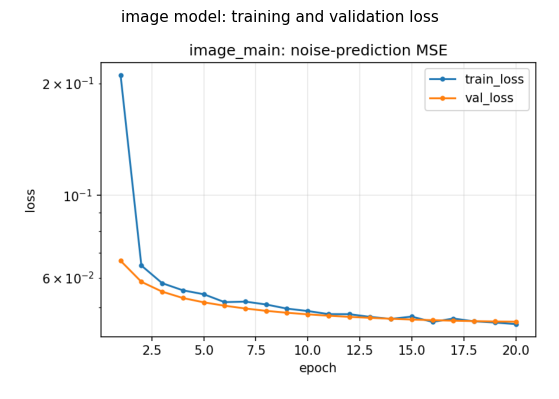

In [14]:
d = "results/task1/image_main"
display(pd.read_csv(f"{d}/train_log.csv").round(4).tail(10))
show_png(f"{d}/loss_curves.png", "image model: training and validation loss", width=7)

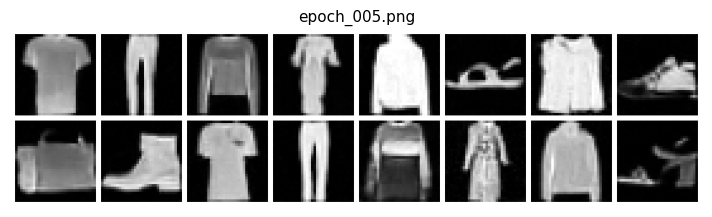

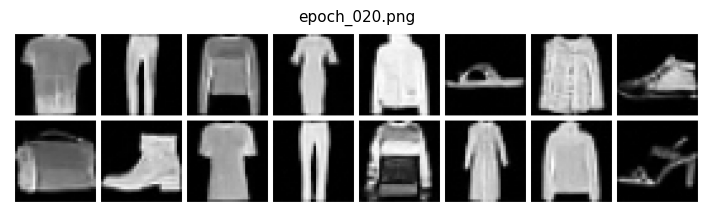

In [15]:
# samples generated DURING training (same noise, one per class) - quality should improve with epochs
fs = sorted(glob.glob("results/task1/image_main/samples/epoch_*.png"))
for f in fs[:1] + fs[-1:]:
    show_png(f, os.path.basename(f), width=9)

### 2.3 Test the denoiser on held-out images, and generate new ones

In [16]:
t0 = time.time()
!python -m task1_diffusion.evaluate --ckpt results/task1/image_main/best.pt {EVAL1}
print(f"elapsed {(time.time()-t0)/60:.1f} min")

[eval] results/task1/image_main/best.pt  (epoch 20, val 0.0457)  device=cuda
[classifier] trained 3 epochs, real test accuracy = 0.880
[gen w=1.0] class_acc=0.8789  FD=0.5098  sec_per_sample=0.0206  pixel_mean=-0.3992  pixel_std=0.6739
[gen w=2.0] class_acc=0.9727  FD=0.6967  sec_per_sample=0.0439  pixel_mean=-0.3554  pixel_std=0.7180
[gen w=4.0] class_acc=0.9922  FD=1.0621  sec_per_sample=0.0439  pixel_mean=-0.3093  pixel_std=0.7580
[eval] wrote results/task1/image_main/eval/metrics.json
elapsed 1.0 min


In [17]:
e = "results/task1/image_main/eval"
m = json.load(open(f"{e}/metrics.json"))
print("DENOISING of held-out test images (noised to level t, then denoised): higher PSNR/SSIM = closer to the original")
display(pd.DataFrame(m["denoising"]).round(3))
print("GENERATION from pure noise: class_acc = how often our own classifier recognises the requested class;"
      " FD = Frechet distance to real images (lower = better); sec_per_sample = speed")
display(pd.DataFrame(m["generation"]).T.round(4))

DENOISING of held-out test images (noised to level t, then denoised): higher PSNR/SSIM = closer to the original


,t,frac,noisy_mse,noisy_psnr,noisy_ssim,onestep_mse,onestep_psnr,onestep_ssim,ddim_mse,ddim_psnr,ddim_ssim
0,49,0.05,0.006,28.163,0.827,0.001,35.156,0.966,0.002,34.475,0.960
1,99,0.10,0.021,22.794,0.670,0.003,31.712,0.937,0.003,31.118,0.929
2,249,0.25,0.119,15.295,0.387,0.009,27.110,0.861,0.010,26.427,0.846
3,499,0.50,0.425,9.740,0.146,0.023,22.866,0.748,0.027,22.126,0.731
4,749,0.75,0.804,6.986,0.035,0.050,19.532,0.606,0.062,18.598,0.578
5,899,0.90,1.021,5.956,0.009,0.099,16.498,0.422,0.135,15.273,0.439


GENERATION from pure noise: class_acc = how often our own classifier recognises the requested class; FD = Frechet distance to real images (lower = better); sec_per_sample = speed


,class_acc,FD,sec_per_sample,pixel_mean,pixel_std
real_test_class_acc,0.8828,0.8828,0.8828,0.8828,0.8828
FD_real_train_vs_real_test(noise floor),1.3766,1.3766,1.3766,1.3766,1.3766
guidance_1.0,0.8789,0.5098,0.0206,-0.3992,0.6739
guidance_2.0,0.9727,0.6967,0.0439,-0.3554,0.7180
guidance_4.0,0.9922,1.0621,0.0439,-0.3093,0.7580


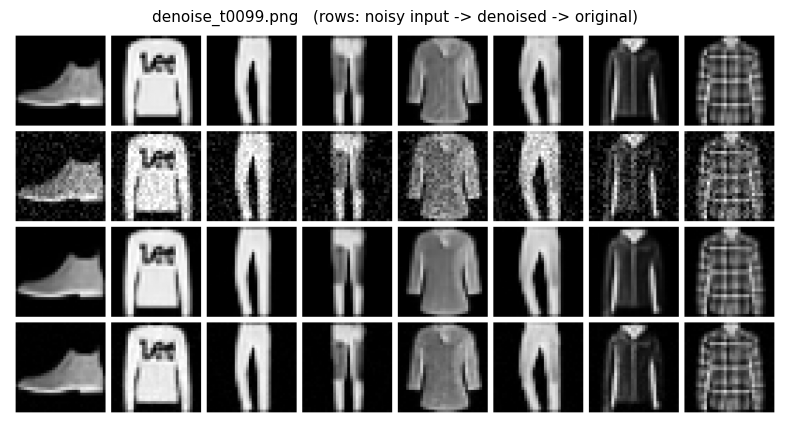

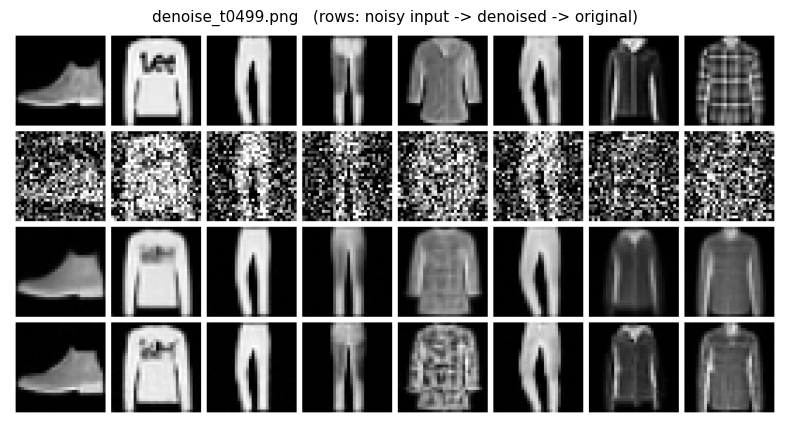

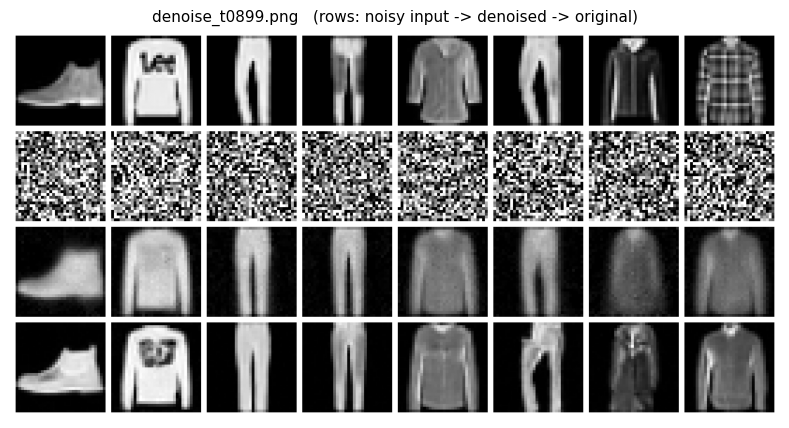

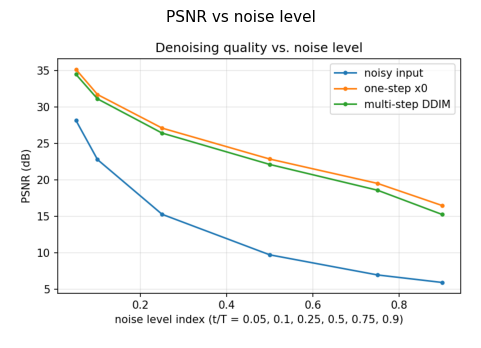

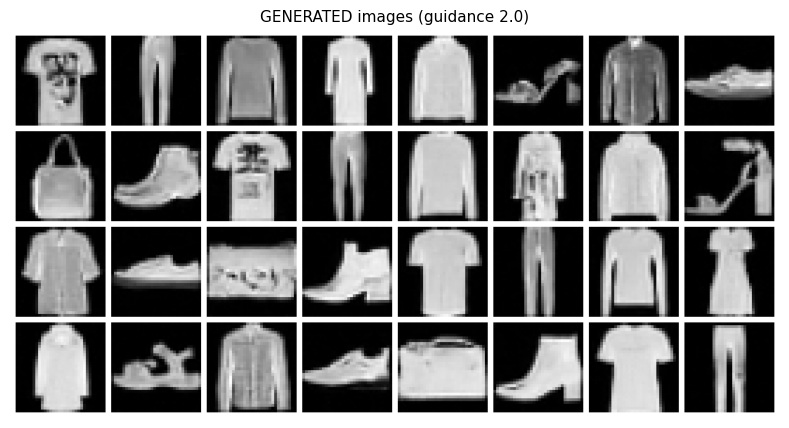

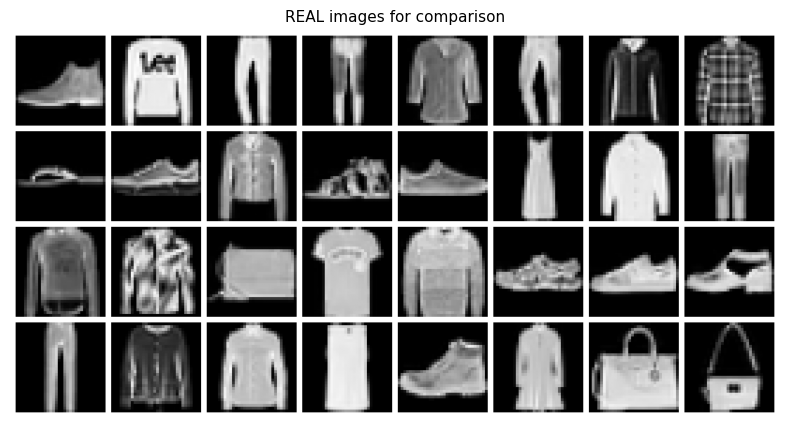

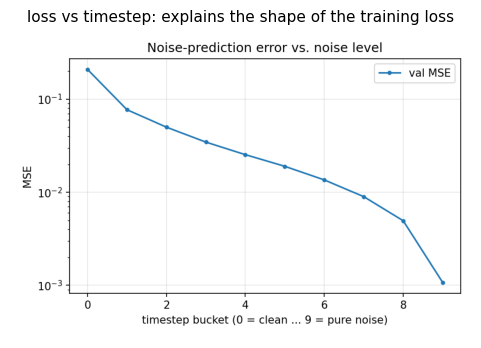

In [18]:
for f in sorted(glob.glob("results/task1/image_main/eval/denoise_t*.png"))[:3]:
    show_png(f, os.path.basename(f) + "   (rows: noisy input -> denoised -> original)", width=10)
show_png(pick("results/task1/image_main/eval/denoising_psnr.png"), "PSNR vs noise level", width=6)
show_png(pick("results/task1/image_main/eval/generated_w2.0.png"), "GENERATED images (guidance 2.0)", width=10)
show_png(pick("results/task1/image_main/eval/real_reference.png"), "REAL images for comparison", width=10)
show_png(pick("results/task1/image_main/eval/loss_by_timestep.png"), "loss vs timestep: explains the shape of the training loss", width=6)

### 2.4 Train the video model (3D UNet) - the same diffusion code, one extra axis

In [19]:
t0 = time.time()
!python -m task1_diffusion.train --task video --schedule cosine --min_snr 5.0 --run_name video_main --out_dir results/task1 --epochs {EP_VID} {AMP} {Q1}
!python -m task1_diffusion.evaluate --ckpt results/task1/video_main/best.pt {EVAL1}
print(f"elapsed {(time.time()-t0)/60:.1f} min")

[data] moving_shapes  train (4000, 1, 8, 32, 32)  val (500, 1, 8, 32, 32)  classes=12  range=[-1.00, 1.00]
[model] 5.14M params | device=cuda | amp=True | out=results/task1/video_main
ep 001/40 | train 0.5659 | val 0.0926 | gnorm 2.76 | lr 1.9e-04 | 6.0 it/s | mem 1393MB | 21s
ep 002/40 | train 0.0442 | val 0.0378 | gnorm 0.35 | lr 3.0e-04 | 6.3 it/s | mem 1393MB | 20s
ep 003/40 | train 0.0339 | val 0.0324 | gnorm 0.23 | lr 3.0e-04 | 6.2 it/s | mem 1393MB | 20s
ep 004/40 | train 0.0336 | val 0.0299 | gnorm 0.15 | lr 3.0e-04 | 6.2 it/s | mem 1393MB | 20s
ep 005/40 | train 0.0299 | val 0.0287 | gnorm 0.17 | lr 2.9e-04 | 6.2 it/s | mem 1393MB | 20s
ep 006/40 | train 0.0289 | val 0.0278 | gnorm 0.14 | lr 2.9e-04 | 6.2 it/s | mem 1393MB | 20s
ep 007/40 | train 0.0298 | val 0.0271 | gnorm 0.13 | lr 2.9e-04 | 6.2 it/s | mem 1393MB | 20s
ep 008/40 | train 0.0264 | val 0.0266 | gnorm 0.13 | lr 2.8e-04 | 6.2 it/s | mem 1393MB | 20s
ep 009/40 | train 0.0256 | val 0.0263 | gnorm 0.12 | lr 2.7e-04 

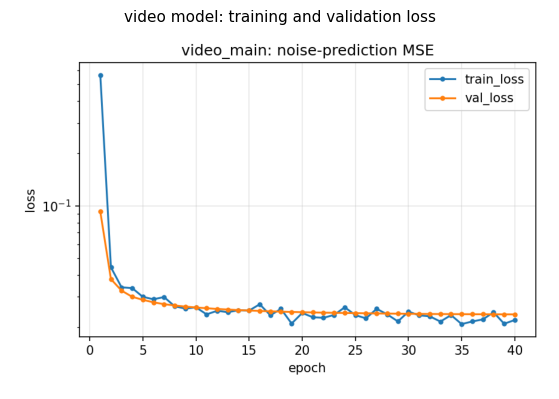

REAL clips (16 shown)


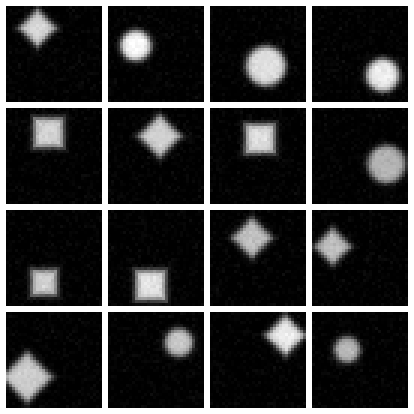

GENERATED clips (guidance 2.0)


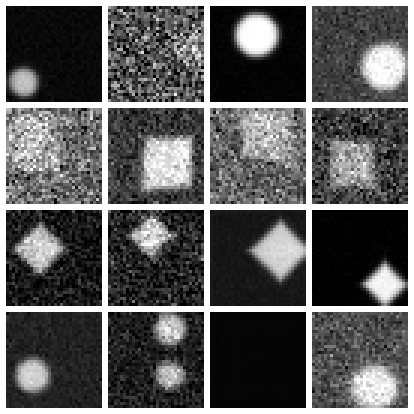

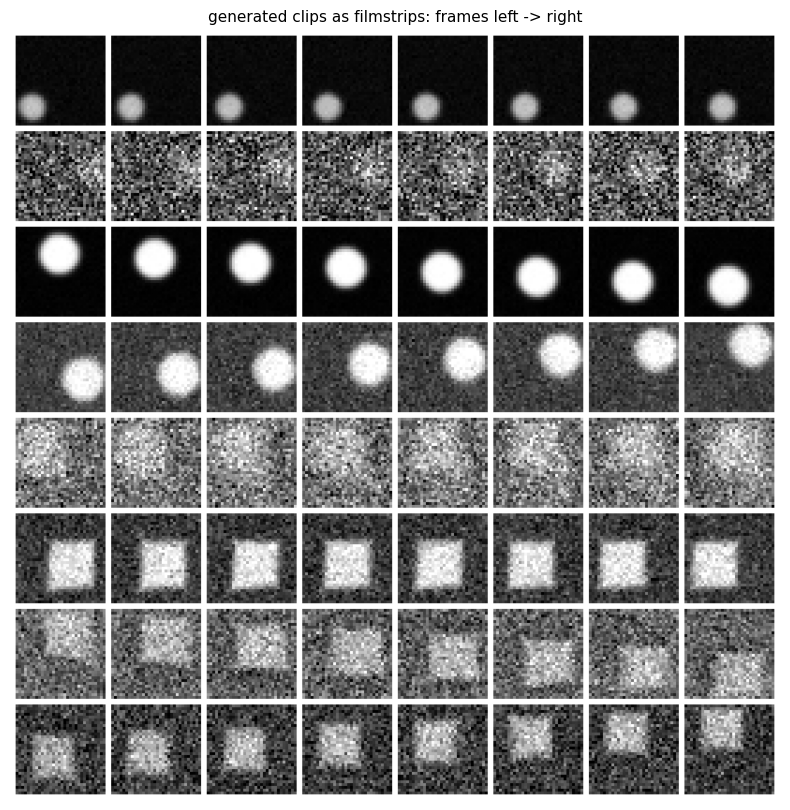

,class_acc,FD,sec_per_sample,pixel_mean,pixel_std,temporal_diff
real_test_class_acc,0.9922,0.9922,0.9922,0.9922,0.9922,0.9922
FD_real_train_vs_real_test(noise floor),0.6506,0.6506,0.6506,0.6506,0.6506,0.6506
real_temporal_diff,0.0794,0.0794,0.0794,0.0794,0.0794,0.0794
guidance_1.0,0.6914,5.0156,0.2821,-0.5104,0.5222,0.1709
guidance_2.0,0.7305,5.0946,0.5617,-0.4604,0.5470,0.1946
guidance_4.0,0.7266,5.5645,0.5615,-0.3944,0.5601,0.2265


temporal_diff = mean |frame t+1 - frame t|: generated clips should move about as much as real ones (video-only metric)


In [20]:
d = "results/task1/video_main"; e = d + "/eval"
show_png(f"{d}/loss_curves.png", "video model: training and validation loss", width=7)
show_gif(pick(f"{e}/real_reference.gif"), "REAL clips (16 shown)", width=420)
show_gif(pick(f"{e}/generated_w2.0.gif"), "GENERATED clips (guidance 2.0)", width=420)
show_png(pick(f"{e}/generated_w2.0_filmstrip.png"), "generated clips as filmstrips: frames left -> right", width=10)
m = json.load(open(f"{e}/metrics.json"))
display(pd.DataFrame(m["generation"]).T.round(4))
print("temporal_diff = mean |frame t+1 - frame t|: generated clips should move about as much as real ones (video-only metric)")

### 2.5 Controlled experiments (image model): noise schedule x loss weighting
Each run changes **one** thing: linear vs cosine schedule, plain MSE vs Min-SNR weighting.

In [21]:
t0 = time.time()
q = "--quick" if QUICK else ""
!python -m task1_diffusion.experiments --tasks image --schedules linear cosine --min_snr 0 5.0 --epochs {EP_ABL} --out_dir results/ablation {AMP} {q}
print(f"elapsed {(time.time()-t0)/60:.1f} min")
show_md("results/ablation/experiment_table.md")


$ /usr/bin/python3 -m task1_diffusion.train --task image --schedule linear --min_snr 0.0 --out_dir results/ablation --run_name image_linear_plain --epochs 8 --amp
[data] fashion_mnist  train (54000, 1, 32, 32)  val (6000, 1, 32, 32)  classes=10  range=[-1.00, 1.00]
[model] 7.71M params | device=cuda | amp=True | out=results/ablation/image_linear_plain
/content/Video-Diffusion-and-LoRA-fine-tuning/task1_diffusion/train.py:146: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  lr_sched.step()
ep 001/8 | train 0.1756 | val 0.0323 | gnorm 1.47 | lr 3.0e-04 | 8.4 it/s | mem 1386MB | 50s
ep 002/8 | train 0.0315 | val 0.0284 | gnorm 0.23 | lr 2.7e-04 | 8.7

# Task 1 - experiment table

| run | best epoch | val MSE | PSNR@t=.5 (dB) | SSIM@t=.5 | best guidance | class acc | FD (floor) | s/sample | train peak MB | train time (s) | params (M) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| image_linear_plain | 8 | 0.0245 | 16.92 | 0.520 | 4.0 | 1.000 | 1.25 (1.38) | 0.045 | 1386 | 410 | 7.71 |
| image_linear_minsnr | 8 | 0.0279 | 17.00 | 0.519 | 4.0 | 0.992 | 1.17 (1.38) | 0.044 | 1386 | 402 | 7.71 |
| image_cosine_plain | 8 | 0.0442 | 21.90 | 0.723 | 4.0 | 0.996 | 1.03 (1.38) | 0.045 | 1387 | 420 | 7.71 |
| image_cosine_minsnr | 8 | 0.0501 | 21.91 | 0.717 | 4.0 | 0.996 | 1.05 (1.38) | 0.045 | 1387 | 431 | 7.71 |

**Limitations.** Single seed per configuration (differences < ~5% are within run-to-run noise); small 32x32 / 8-frame data; Frechet distance uses features of our own small classifier, so it is *not* comparable with published FID/FVD values; val MSE of runs with different schedules is measured under different noise-level mixtures, so compare PSNR / class accuracy / FD across schedules, not val MSE alone.


# 3. Task 2 - LoRA fine-tuning of an open-source video model

**Model:** `damo-vilab/text-to-video-ms-1.7b` (Hugging Face, text -> video). **LoRA:** freeze the pretrained weights `W0` and learn a tiny update `y = W0 x + (alpha/r) * B(A x)` with `A: r x in`, `B: out x r`, `B = 0` at the start, so training begins exactly at the base model. We adapt only the attention projections, so only ~1 % of the parameters are trained and a checkpoint is a few MB.

**Question we test:** can LoRA teach the model a *style / concept* from 48 clips - and does it compose it with something unseen (a **yellow square** is held out of training)?

### 3.1 The dataset

In [5]:
!git -C /content/Video-Diffusion-and-LoRA-fine-tuning pull
!grep -n "image_embeds" /content/Video-Diffusion-and-LoRA-fine-tuning/task2_lora/evaluate_lora.py

remote: Enumerating objects: 7, done.
remote: Counting objects: 100% (7/7), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 4 (delta 3), reused 4 (delta 3), pack-reused 0 (from 0)
Unpacking objects: 100% (4/4), 674 bytes | 674.00 KiB/s, done.
From https://github.com/Aryam-21/Video-Diffusion-and-LoRA-fine-tuning
   e87827b..64a1d58  main       -> origin/main
Updating e87827b..64a1d58
Fast-forward
 task2_lora/evaluate_lora.py | 9 ++++++---
 1 file changed, 6 insertions(+), 3 deletions(-)
51:        # Use the model's normal forward pass: its CLIPOutput always has `image_embeds` / `text_embeds`. (Newer transformers versions
54:        img = F.normalize(out.image_embeds.float(), dim=-1)


/content/Video-Diffusion-and-LoRA-fine-tuning/task2_lora/make_toy_dataset.py:45: RuntimeWarning: overflow encountered in exp
  m = 1 / (1 + np.exp(-(r - d) / 1.2))
wrote 56 clips + metadata.jsonl + eval_prompts.json to data/toy_videos
{"file": "clips/train_000.mp4", "caption": "a red circle moving from left to right on a black background", "split": "train"}

{
  "seen": [
    "a red circle moving from left to right on a black background",
    "a blue square moving from top to bottom on a black background",
    "a green circle moving from right to left on a black background"
  ],
  "unseen": [
    "a yellow square moving from left to right on a black background",
    "a yellow square moving from bottom to top on a black background"
  ]
}
4 example clips shown side by side: ['train_000.mp4', 'train_001.mp4', 'train_002.mp4', 'train_003.mp4']


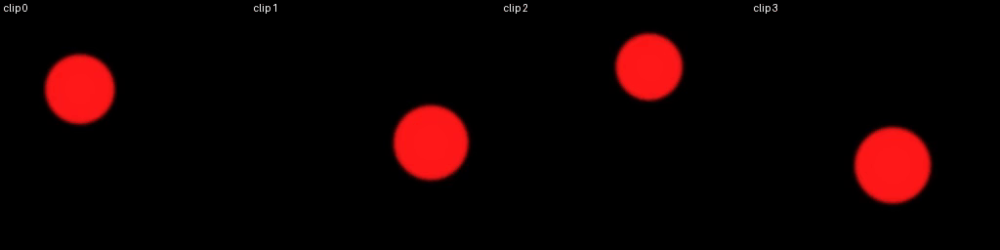

In [6]:
nt, nv = ("16", "4") if QUICK else ("48", "8")
!python -m task2_lora.make_toy_dataset --out data/toy_videos --n_train {nt} --n_val {nv}
print(open("data/toy_videos/metadata.jsonl").readlines()[0])
print(open("data/toy_videos/eval_prompts.json").read())
clips = sorted(glob.glob("data/toy_videos/**/*.mp4", recursive=True))[:4]
print(len(clips), "example clips shown side by side:", [os.path.basename(c) for c in clips])
side_by_side(clips, [f"clip {i}" for i in range(len(clips))], "toy_examples.gif", fps=6, width=900)

### 3.2 Experiments: LoRA rank (capacity) at a fixed learning rate
Each run caches nothing special: it trains for `EP_LORA` epochs, saves a **checkpoint every epoch** plus `best.pt` (lowest validation loss), and logs loss / time / GPU memory. Epoch 0 in the curves is the *base model* - the baseline to beat.

In [7]:
t0 = time.time()
SWEEP = "--quick" if QUICK else f"--ranks 4 16 --lrs 1e-4 --epochs {EP_LORA}"
!python -m task2_lora.sweep {SWEEP}
print(f"elapsed {(time.time()-t0)/60:.1f} min")


$ /usr/bin/python3 -m task2_lora.train_lora --data_dir data/toy_videos --rank 4 --lr 0.0001 --targets attn --epochs 10 --out_dir runs/lora/r4_lr0.0001_attn --sample_every 5
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  40% 2/5 [00:01<00:02,  1.15it/s]
Loading weights:   0% 0/372 [00:00<?, ?it/s]
Loading weights:  12% 46/372 [00:00<00:00, 453.80it/s]
Loading weights:  44% 164/372 [00:00<00:00, 878.48it/s]
Loading weights: 100% 372/372 [00:00<00:00, 919.97it/s] 
Loading pipeline components...: 100% 5/5 [00:02<00:00,  2.18it/s]
The TextToVideoSDPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 
[cache] encoded 10/56 clips
[cache] encoded 20/56 clips
[cache] encoded 30/56 clips
[cache] 

# LoRA experiments

| run | rank | lr | targets | trainable params | baseline val | best val | best epoch | final val | overfit? | time (min) | peak GB |
|---|---|---|---|---|---|---|---|---|---|---|---|
| r16_lr0.0001_attn | 16 | 0.0001 | attn | 6.65M | 0.03128 | 0.00511 | 10 | 0.00511 | no | 11.2 | 5.6 |
| r4_lr0.0001_attn | 4 | 0.0001 | attn | 1.66M | 0.03128 | 0.00579 | 10 | 0.00579 | no | 11.3 | 5.5 |


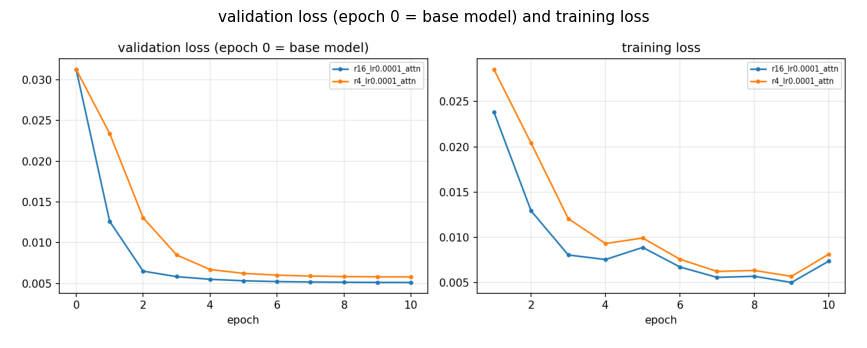

In [8]:
show_md("runs/lora/lora_experiments.md")
show_png("runs/lora/lora_curves.png", "validation loss (epoch 0 = base model) and training loss", width=11)

In [9]:
# pick the best run = lowest validation loss; this is the checkpoint we evaluate and present
runs = {os.path.dirname(p): json.load(open(p)) for p in glob.glob("runs/lora/*/summary.json")}
BEST = min(runs, key=lambda r: runs[r]["best_val_loss"])
s = runs[BEST]
print(f"best run: {BEST}\n  rank {s['rank']}, lr {s['lr']}, best epoch {s['best_epoch']}, "
      f"val {s['best_val_loss']:.5f} (base model {s['baseline_val_loss']:.5f}), trainable params {s['trainable_params']:,}")
print("checkpoints:", sorted(os.listdir(f"{BEST}/checkpoints"))[:6], "...")
print("size of best.pt: %.1f MB (the 1.7B base model is ~3.4 GB)" % (os.path.getsize(f"{BEST}/checkpoints/best.pt") / 2**20))

best run: runs/lora/r16_lr0.0001_attn
  rank 16, lr 0.0001, best epoch 10, val 0.00511 (base model 0.03128), trainable params 6,645,760
checkpoints: ['best.pt', 'epoch_001.pt', 'epoch_002.pt', 'epoch_003.pt', 'epoch_004.pt', 'epoch_005.pt'] ...
size of best.pt: 25.5 MB (the 1.7B base model is ~3.4 GB)


### 3.3 Base model vs LoRA - same prompt, same seed, same noise

In [10]:
t0 = time.time()
sc = "0 1.0" if QUICK else "0 0.5 1.0 1.5"
sd = "0" if QUICK else "0 1"
!python -m task2_lora.evaluate_lora --run_dir {BEST} --ckpts best.pt --scales {sc} --seeds {sd}
print(f"elapsed {(time.time()-t0)/60:.1f} min")
show_md(f"{BEST}/eval/clip_scores.md")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)
Loading pipeline components...:  80% 4/5 [00:00<00:00, 14.47it/s]
Loading weights: 100% 372/372 [00:00<00:00, 4442.02it/s]
Loading pipeline components...: 100% 5/5 [00:00<00:00,  6.12it/s]
The TextToVideoSDPipeline has been deprecated and will not receive bug fixes or feature updates after Diffusers version 0.33.1. 
Loading weights: 100% 398/398 [00:02<00:00, 186.55it/s]
[eval] best.pt scale=0.0 done
[eval] best.pt scale=0.5 done
[eval] best.pt scale=1.0 done
[eval] best.pt scale=1.5 done
| model | LoRA scale | prompts | CLIP text-video | CLIP temporal | n |
|---|---|---|---|---|---|
| base model | 0.0 | seen | 0.2865 | 0.9866 | 6 |
| best.pt | 0.5 | seen | 0.2830 | 0.9787 | 6 |
| best.pt | 1.0 | seen | 0.2886 | 0.9527 | 6 |
| bes

| model | LoRA scale | prompts | CLIP text-video | CLIP temporal | n |
|---|---|---|---|---|---|
| base model | 0.0 | seen | 0.2865 | 0.9866 | 6 |
| best.pt | 0.5 | seen | 0.2830 | 0.9787 | 6 |
| best.pt | 1.0 | seen | 0.2886 | 0.9527 | 6 |
| best.pt | 1.5 | seen | 0.2968 | 0.9479 | 6 |
| base model | 0.0 | unseen | 0.3176 | 0.9845 | 4 |
| best.pt | 0.5 | unseen | 0.3178 | 0.9773 | 4 |
| best.pt | 1.0 | unseen | 0.2981 | 0.9309 | 4 |
| best.pt | 1.5 | unseen | 0.3049 | 0.9229 | 4 |


[seen] prompt: a red circle moving from left to right on a black background


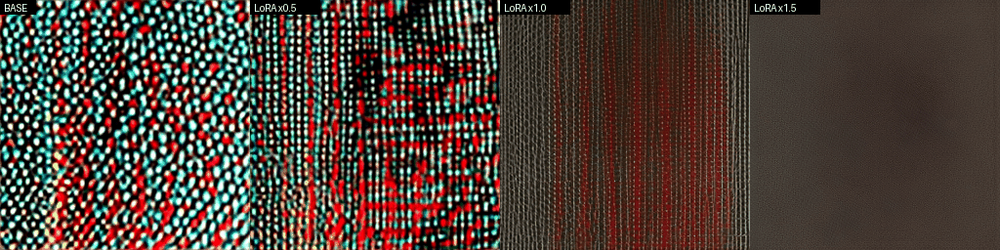

[unseen] prompt: a yellow square moving from left to right on a black background


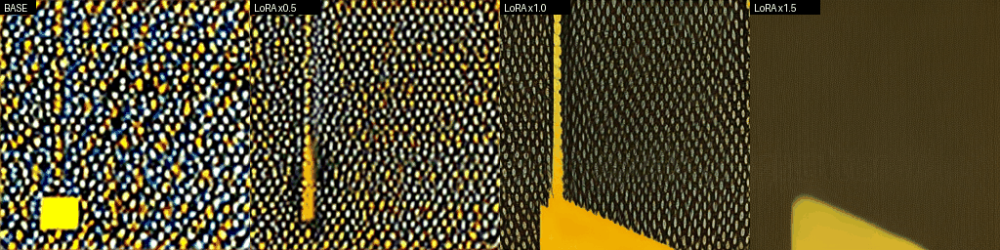

In [11]:
prompts = json.load(open("data/toy_videos/eval_prompts.json"))
scales = [0.0, 1.0] if QUICK else [0.0, 0.5, 1.0, 1.5]
for group, idx in [("seen", 0), ("unseen", 0)]:
    paths = [f"{BEST}/eval/videos/best_s{sc_}_{group}{idx}_seed0.gif" for sc_ in scales]
    labels = ["BASE" if sc_ == 0 else f"LoRA x{sc_}" for sc_ in scales]
    ok = [(p, l) for p, l in zip(paths, labels) if os.path.exists(p)]
    if ok:
        print(f"[{group}] prompt: {prompts[group][idx]}")
        side_by_side([p for p, _ in ok], [l for _, l in ok], f"compare_{group}.gif", fps=6)

['best.pt', 'epoch_001.pt', 'epoch_002.pt', 'epoch_003.pt', 'epoch_004.pt', 'epoch_005.pt', 'epoch_006.pt', 'epoch_007.pt', 'epoch_008.pt', 'epoch_009.pt', 'epoch_010.pt']
epoch_005_prompt0.gif


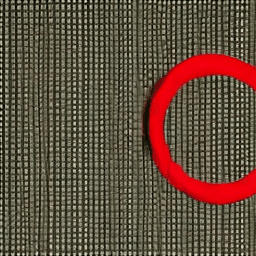

epoch_010_prompt1.gif


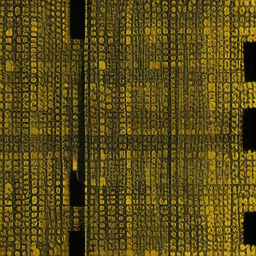

In [12]:
# the same checkpoints from different epochs: lowest validation loss does not always look best
print(sorted(os.listdir(f"{BEST}/checkpoints")))
g = sorted(glob.glob(f"{BEST}/samples/*.gif"))
for f in g[:1] + g[-1:]:
    show_gif(f, os.path.basename(f), width=300)

# 4. Save everything before the session ends
Colab deletes all files when the runtime stops. Copy results to Google Drive (or download the zip).

In [13]:
from google.colab import drive
drive.mount("/content/drive")
dst = f"/content/drive/MyDrive/video_diffusion_results_{'quick' if QUICK else 'full'}"
!mkdir -p "{dst}"
!zip -qr results_all.zip results runs data/toy_videos/eval_prompts.json compare_*.gif toy_examples.gif -x "runs/lora/*/checkpoints/epoch_*.pt"
!cp results_all.zip "{dst}/"
print("saved to", dst)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saved to /content/drive/MyDrive/video_diffusion_results_full


In [14]:
!python -m pytest task1_diffusion/tests task2_lora/tests -q


.....................                                                    [100%]
21 passed in 6.17s
